In [4]:
import pandas as pd
import requests
import zipfile
import io
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
# Descargar el archivo oficial desde UCI
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
response = requests.get(url, timeout=120)
response.raise_for_status()

In [6]:
# Buscar el CSV dentro del ZIP principal o de los ZIP internos
def buscar_csv(contenido, nombres_preferidos):
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        archivos = z.namelist()

        # Buscar primero bank-full.csv y luego bank.csv
        for nombre_objetivo in nombres_preferidos:
            for nombre in archivos:
                if nombre.lower().endswith(nombre_objetivo.lower()):
                    datos = z.read(nombre)
                    return datos, nombre

        # Si hay ZIP internos, buscar también dentro de ellos
        for nombre in archivos:
            if nombre.lower().endswith(".zip"):
                resultado = buscar_csv(
                    z.read(nombre),
                    nombres_preferidos
                )
                if resultado is not None:
                    return resultado

    return None

resultado = buscar_csv(
    response.content,
    ["bank-full.csv", "bank.csv"]
)

if resultado is None:
    raise FileNotFoundError(
        "No se encontró bank-full.csv ni bank.csv dentro del ZIP."
    )

contenido_csv, archivo_encontrado = resultado

# El CSV de UCI usa punto y coma como separador
df = pd.read_csv(
    io.BytesIO(contenido_csv),
    sep=";",
    na_values=["unknown", "NA", ""]
)

print("Archivo cargado:", archivo_encontrado)
print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 10 filas:")
display(df.head(10))

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo_de_dato"))

print("\nValores faltantes por columna:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("valores_faltantes")
)

print("\nDistribución de la variable objetivo (y):")
display(df["y"].value_counts(dropna=False).to_frame("cantidad"))

print("\nPorcentaje de cada clase:")
display(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("porcentaje")
)

Archivo cargado: bank-full.csv
Dimensiones: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 10 filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no
5,35,management,married,tertiary,no,231,yes,no,NaN,5,may,139,1,-1,0,NaN,no
6,28,management,single,tertiary,no,447,yes,yes,NaN,5,may,217,1,-1,0,NaN,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,NaN,5,may,380,1,-1,0,NaN,no
8,58,retired,married,primary,no,121,yes,no,NaN,5,may,50,1,-1,0,NaN,no
9,43,technician,single,secondary,no,593,yes,no,NaN,5,may,55,1,-1,0,NaN,no



Tipos de datos:


,tipo_de_dato
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Valores faltantes por columna:


,valores_faltantes
poutcome,36959
contact,13020
education,1857
job,288
age,0
default,0
balance,0
housing,0
marital,0
loan,0



Distribución de la variable objetivo (y):


,cantidad
y,
no,39922
yes,5289



Porcentaje de cada clase:


,porcentaje
y,
no,88.3
yes,11.7


In [7]:
# Normalizar cadenas vacías como valores ausentes reales
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 5 filas:")
display(df.head())

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nDuplicados exactos:", df.duplicated().sum())

Dimensiones: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 5 filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no



Tipos de datos:


,tipo
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Duplicados exactos: 0


In [8]:
# Resumen de valores ausentes
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_ausentes": df.isna().sum(),
    "porcentaje_ausente": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
}).sort_values("porcentaje_ausente", ascending=False)

display(calidad)

,tipo,valores_ausentes,porcentaje_ausente,valores_unicos
poutcome,str,36959,81.75,3
contact,str,13020,28.80,2
education,str,1857,4.11,3
job,str,288,0.64,11
age,int64,0,0.00,77
default,str,0,0.00,2
balance,int64,0,0.00,7168
housing,str,0,0.00,2
marital,str,0,0.00,3
loan,str,0,0.00,2


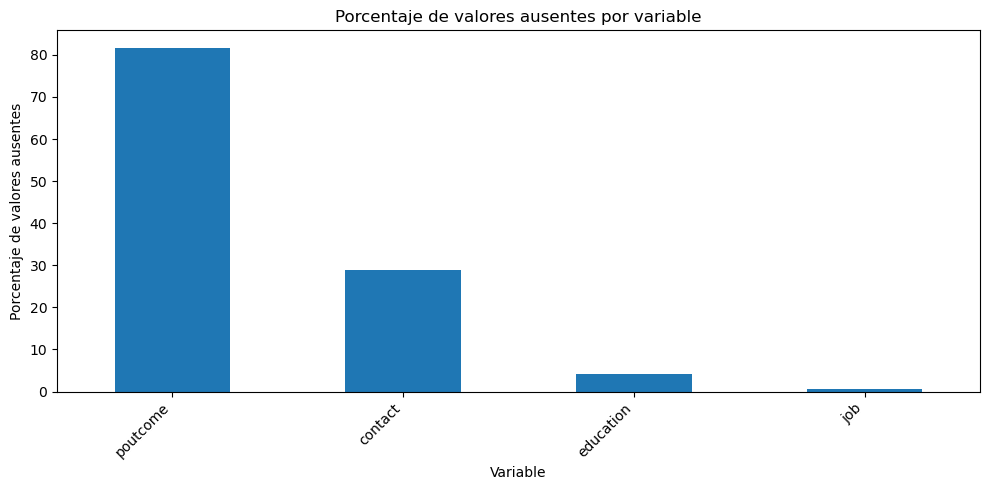

In [9]:
# Gráfica de porcentaje de ausentes
ausentes = (df.isna().mean() * 100).sort_values(ascending=False)
ausentes = ausentes[ausentes > 0]

if len(ausentes) > 0:
    plt.figure(figsize=(10, 5))
    ausentes.plot(kind="bar")
    plt.title("Porcentaje de valores ausentes por variable")
    plt.xlabel("Variable")
    plt.ylabel("Porcentaje de valores ausentes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No se detectaron valores ausentes reales.")

,cantidad,porcentaje
y,,
no,39922,88.3
yes,5289,11.7


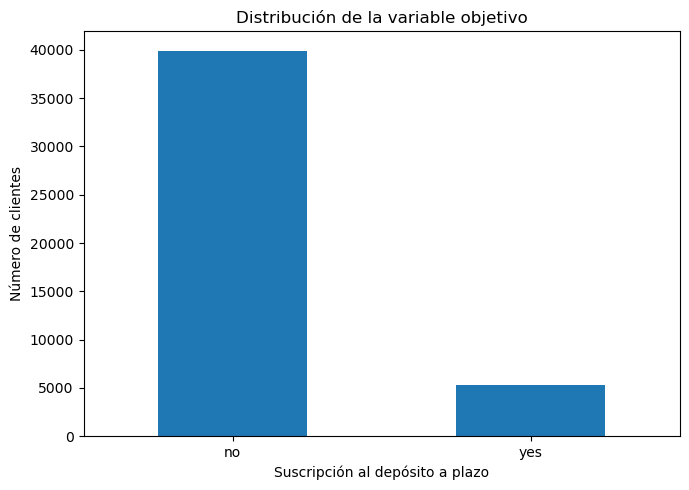

In [10]:
conteo_y = df["y"].value_counts()
porcentaje_y = df["y"].value_counts(normalize=True) * 100

resumen_y = pd.DataFrame({
    "cantidad": conteo_y,
    "porcentaje": porcentaje_y.round(2)
})

display(resumen_y)

plt.figure(figsize=(7, 5))
conteo_y.plot(kind="bar")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Suscripción al depósito a plazo")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


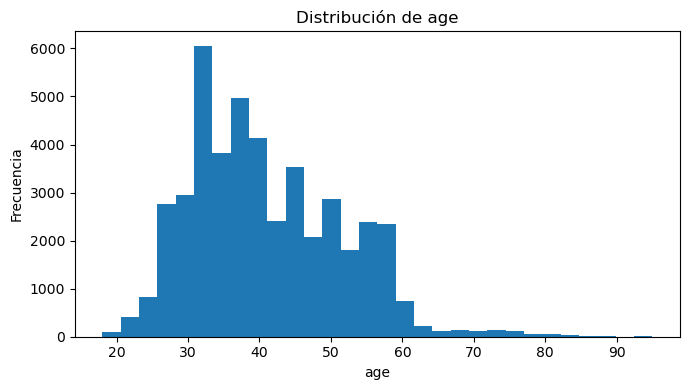

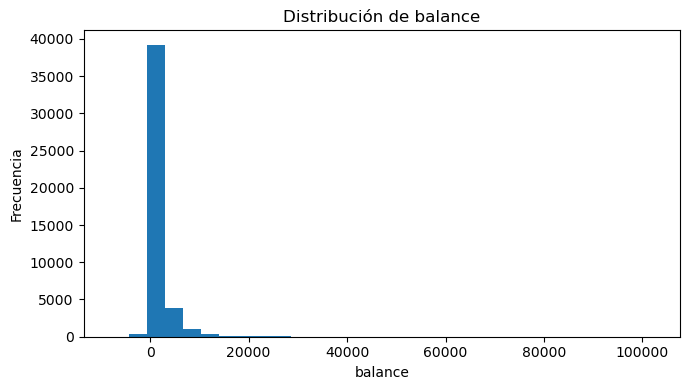

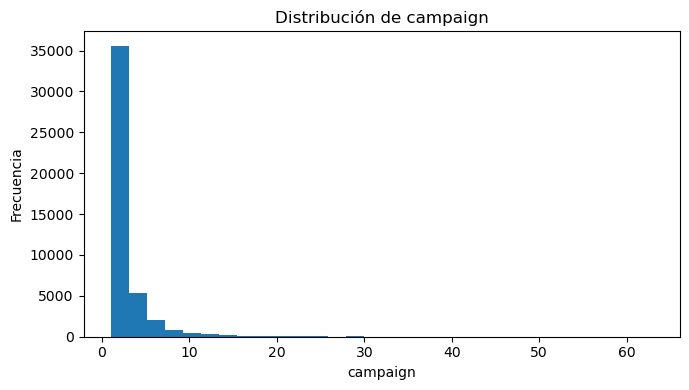

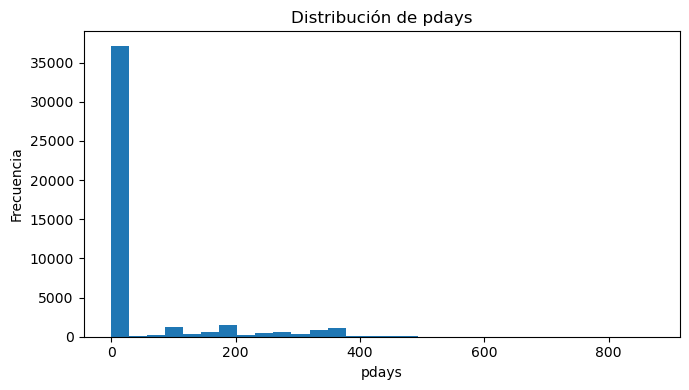

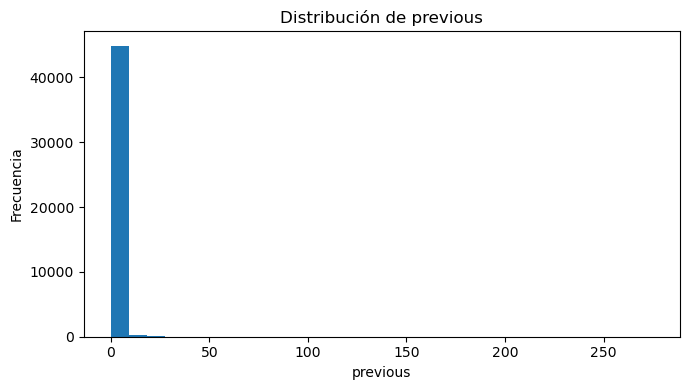

In [11]:
numericas = df.select_dtypes(include="number")

display(numericas.describe().T)

# Histogramas de variables seleccionadas
variables = [
    "age", "balance", "campaign",
    "pdays", "previous"
]

for variable in variables:
    if variable in df.columns:
        valores = pd.to_numeric(df[variable], errors="coerce").dropna()

        plt.figure(figsize=(7, 4))
        plt.hist(valores, bins=30)
        plt.title(f"Distribución de {variable}")
        plt.xlabel(variable)
        plt.ylabel("Frecuencia")
        plt.tight_layout()
        plt.show()


In [12]:
categoricas = df.select_dtypes(include=["object", "category"]).columns

for variable in categoricas:
    print(f"\nDistribución de {variable}:")
    display(
        df[variable]
        .value_counts(dropna=False)
        .head(15)
        .to_frame("cantidad")
    )


Distribución de job:


C:\Users\delfi\AppData\Local\Temp\ipykernel_29996\899706345.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include=["object", "category"]).columns


,cantidad
job,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303



Distribución de marital:


,cantidad
marital,
married,27214
single,12790
divorced,5207


...

,cantidad
month,
may,13766
jul,6895
aug,6247
jun,5341
nov,3970
apr,2932
feb,2649
jan,1403
oct,738



Distribución de poutcome:


,cantidad
poutcome,
NaN,36959
failure,4901
other,1840
success,1511



Distribución de y:


,cantidad
y,
no,39922
yes,5289



Porcentaje de suscripción por job:


y,no,yes
job,,
student,71.32,28.68
retired,77.21,22.79
unemployed,84.50,15.50
management,86.24,13.76
admin.,87.80,12.20
self-employed,88.16,11.84
technician,88.94,11.06
services,91.12,8.88
housemaid,91.21,8.79


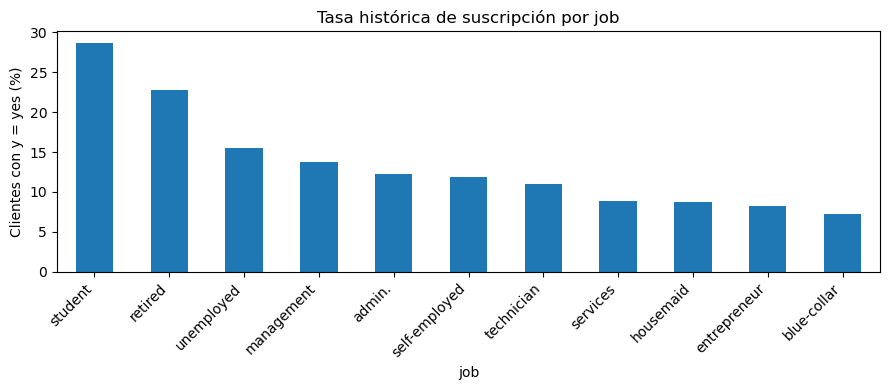


Porcentaje de suscripción por marital:


y,no,yes
marital,,
single,85.05,14.95
divorced,88.05,11.95
married,89.88,10.12


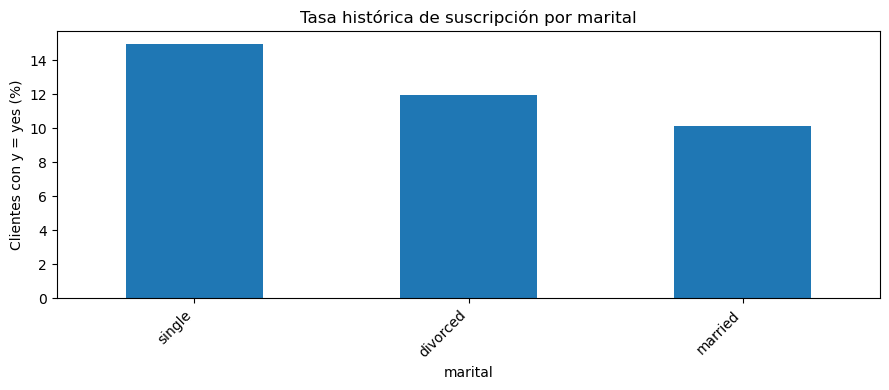


Porcentaje de suscripción por education:


y,no,yes
education,,
tertiary,84.99,15.01
secondary,89.44,10.56
primary,91.37,8.63


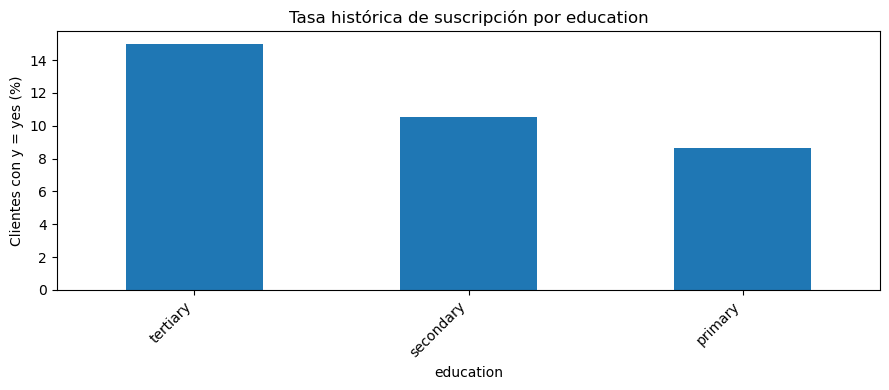


Porcentaje de suscripción por housing:


y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


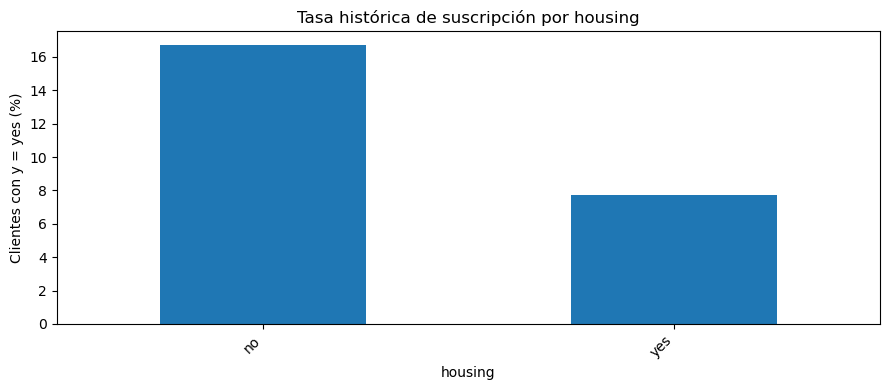


Porcentaje de suscripción por loan:


y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


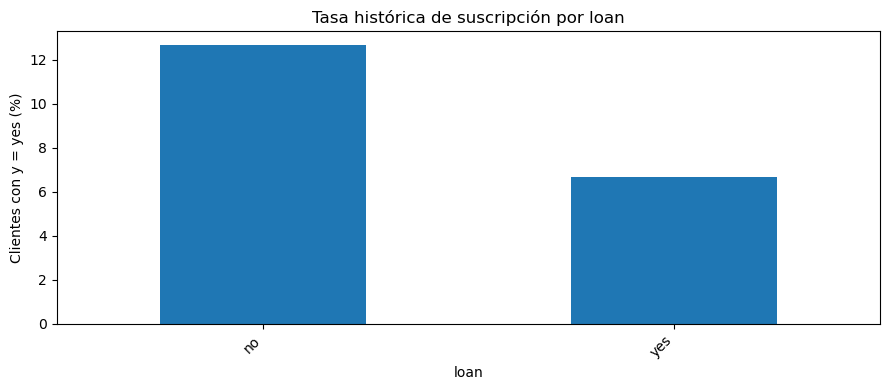


Porcentaje de suscripción por contact:


y,no,yes
contact,,
cellular,85.08,14.92
telephone,86.58,13.42


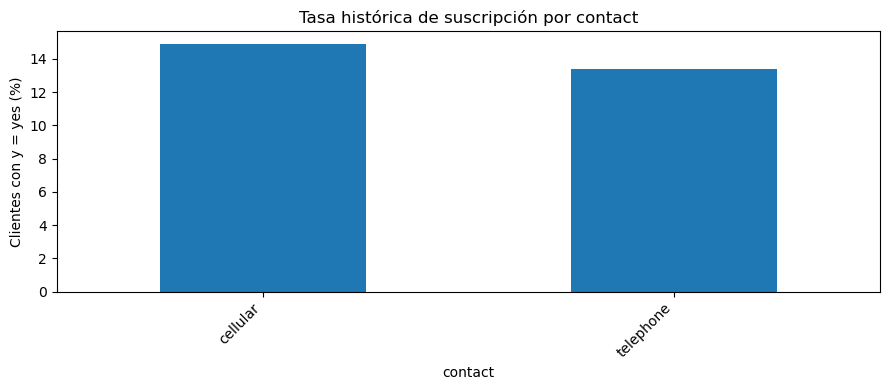


Porcentaje de suscripción por poutcome:


y,no,yes
poutcome,,
success,35.27,64.73
other,83.32,16.68
failure,87.39,12.61


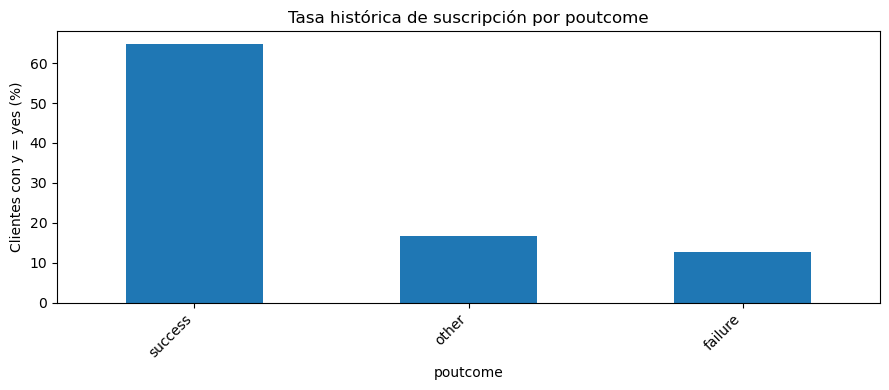

In [13]:
variables_categoricas = [
    "job", "marital", "education",
    "housing", "loan", "contact", "poutcome"
]

for variable in variables_categoricas:
    if variable in df.columns:
        tabla = pd.crosstab(
            df[variable],
            df["y"],
            normalize="index"
        ) * 100

        if "yes" in tabla.columns:
            tabla = tabla.sort_values("yes", ascending=False)

        print(f"\nPorcentaje de suscripción por {variable}:")
        display(tabla.round(2))

        if "yes" in tabla.columns:
            plt.figure(figsize=(9, 4))
            tabla["yes"].plot(kind="bar")
            plt.title(f"Tasa histórica de suscripción por {variable}")
            plt.xlabel(variable)
            plt.ylabel("Clientes con y = yes (%)")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            plt.show()


Resumen de age según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,40.84,39.0,10.17,18,95
yes,5289,41.67,38.0,13.50,18,95


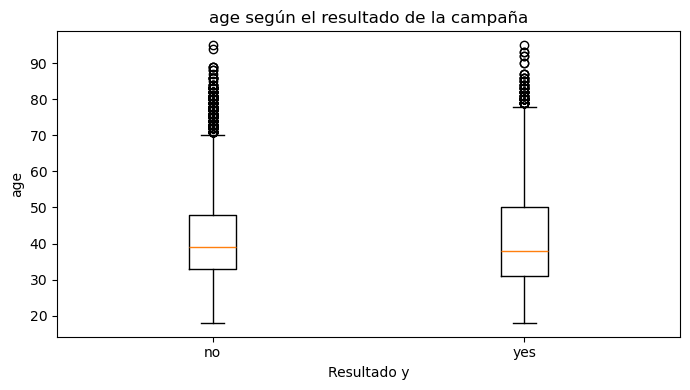


Resumen de balance según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,1303.71,417.0,2974.2,-8019,102127
yes,5289,1804.27,733.0,3501.1,-3058,81204


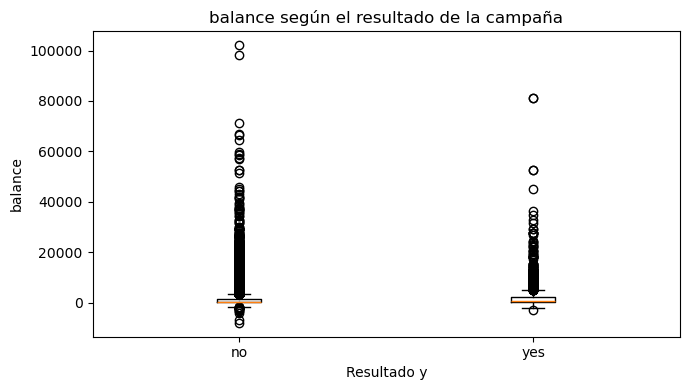


Resumen de campaign según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,2.85,2.0,3.21,1,63
yes,5289,2.14,2.0,1.92,1,32


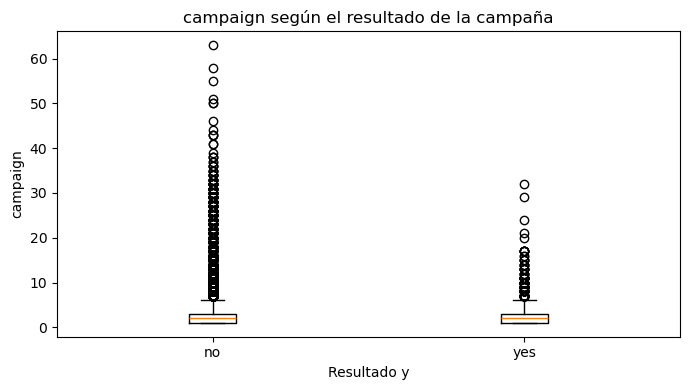


Resumen de previous según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,0.50,0.0,2.26,0,275
yes,5289,1.17,0.0,2.55,0,58


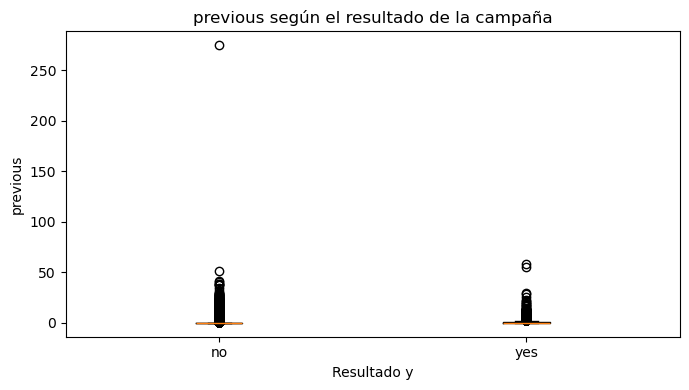


Resumen de duration según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,221.18,164.0,207.38,0,4918
yes,5289,537.29,426.0,392.53,8,3881


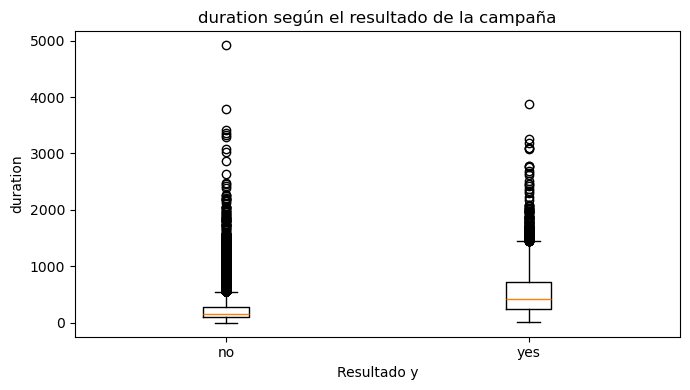

In [14]:
variables_numericas = ["age", "balance", "campaign", "previous", "duration"]

for variable in variables_numericas:
    if variable in df.columns:
        print(f"\nResumen de {variable} según y:")
        display(
            df.groupby("y")[variable]
              .agg(["count", "mean", "median", "std", "min", "max"])
              .round(2)
        )

        grupos = [
            df.loc[df["y"] == clase, variable].dropna()
            for clase in ["no", "yes"]
        ]

        plt.figure(figsize=(7, 4))
        plt.boxplot(grupos, tick_labels=["no", "yes"])
        plt.title(f"{variable} según el resultado de la campaña")
        plt.xlabel("Resultado y")
        plt.ylabel(variable)
        plt.tight_layout()
        plt.show()

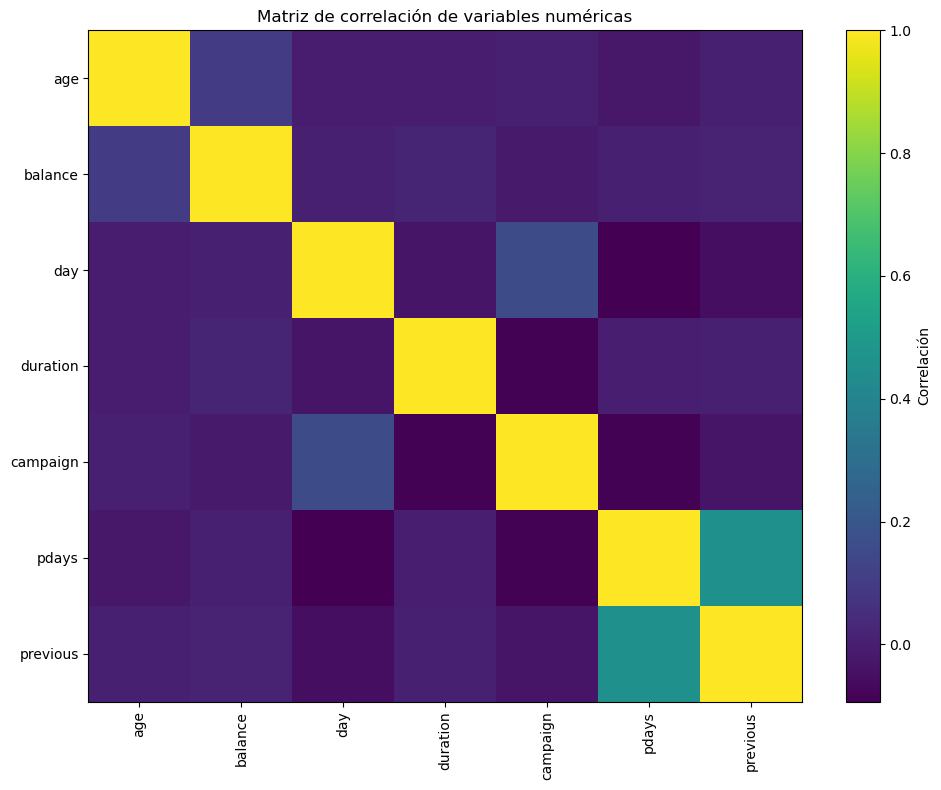

In [18]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto", cmap="viridis")
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()